In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

#   Baca data
df = pd.read_csv('/content/data_antrian.csv')

# ubah time columns ke datetime objects
df['ArrivalTime'] = pd.to_datetime(df['ArrivalTime'])
df['ServiceStartTime'] = pd.to_datetime(df['ServiceStartTime'])
df['ServiceEndTime'] = pd.to_datetime(df['ServiceEndTime'])

# Hitung waktu tunggu dan pelayanan
df['waktu_tunggu'] = df['ServiceStartTime'] - df['ArrivalTime']
df['waktu_pelayanan'] = df['ServiceEndTime'] - df['ServiceStartTime']

# Konversi ke menit
df['waktu_tunggu'] = pd.to_timedelta(df['waktu_tunggu'])
df['waktu_pelayanan'] = pd.to_timedelta(df['waktu_pelayanan'])

df['waktu_tunggu_(menit)'] = df['waktu_tunggu'].dt.total_seconds() / 60
df['waktu_pelayanan_(menit)'] = df['waktu_pelayanan'].dt.total_seconds() / 60

# Menyimpan hasil perhitungan ke file baru
df.to_csv('data_antrian_hasil.csv', index=False)

/tmp/ipython-input-570097814.py:9: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['ArrivalTime'] = pd.to_datetime(df['ArrivalTime'])
/tmp/ipython-input-570097814.py:10: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['ServiceStartTime'] = pd.to_datetime(df['ServiceStartTime'])
/tmp/ipython-input-570097814.py:11: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['ServiceEndTime'] = pd.to_datetime(df['ServiceEndTime'])


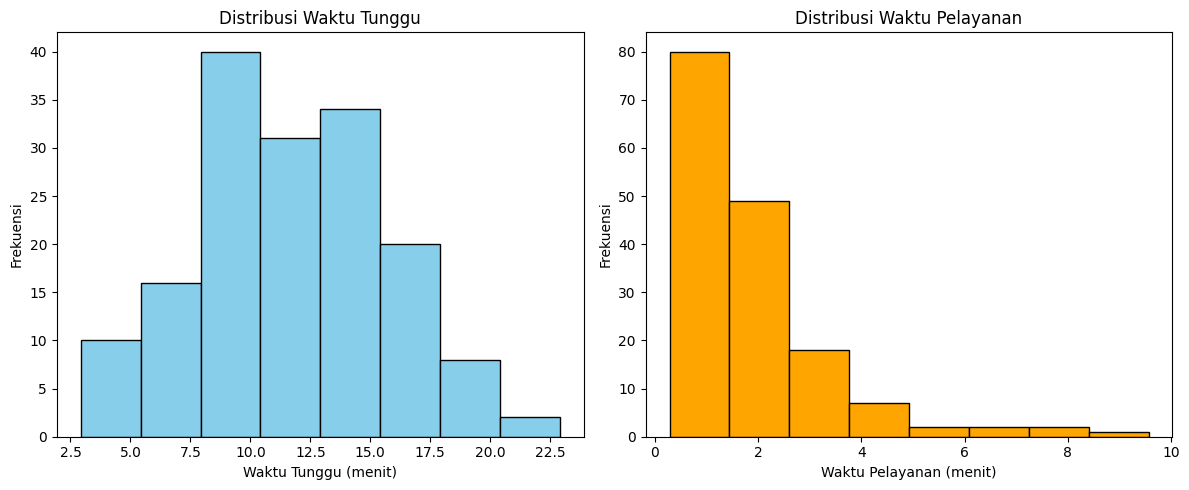

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Baca data
df = pd.read_csv('/content/data_antrian_hasil.csv')

# Statistik
def calculate_statistics(data):
    data_min = round(data.min(), 3)
    data_max = round(data.max(), 3)
    data_range = round(data_max - data_min, 3)
    k = int(np.ceil(np.log2(len(data))))  # Banyak kelas
    p = round(data_range / k, 3)          # Panjang kelas
    return data_min, data_max, data_range, k, p

wt_min, wt_max, wt_range, wt_k, wt_p = calculate_statistics(df['waktu_tunggu_(menit)'])
wp_min, wp_max, wp_range, wp_k, wp_p = calculate_statistics(df['waktu_pelayanan_(menit)'])

print(f"Waktu Tunggu: Min={wt_min}, Max={wt_max}, Range={wt_range}, Kelas={wt_k}, Panjang Kelas={wt_p}")
print(f"Waktu Pelayanan: Min={wp_min}, Max={wp_max}, Range={wp_range}, Kelas={wp_k}, Panjang Kelas={wp_p}")

# Visualisasi
plt.figure(figsize=(12, 5))

# Histogram waktu tunggu
plt.subplot(1, 2, 1)
plt.hist(df['waktu_tunggu_(menit)'], color='skyblue', bins=wt_k, edgecolor='black')
plt.title('Distribusi Waktu Tunggu')
plt.xlabel('Waktu Tunggu (menit)')
plt.ylabel('Frekuensi')

# Histogram waktu pelayanan
plt.subplot(1, 2, 2)
plt.hist(df['waktu_pelayanan_(menit)'], color='orange',  bins=wp_k,  edgecolor='black')
plt.title('Distribusi Waktu Pelayanan')
plt.xlabel('Waktu Pelayanan (menit)')
plt.ylabel('Frekuensi')

plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd

# Baca data
df = pd.read_csv('/content/data_antrian_hasil.csv')

# hitung nilai total dan rata-rata
total_waktu_tunggu = df['waktu_tunggu_(menit)'].sum()
total_waktu_pelayanan = df['waktu_pelayanan_(menit)'].sum()
jumlah_pelanggan = len(df)

rata_rata_waktu_tunggu = total_waktu_tunggu/jumlah_pelanggan
rata_rata_waktu_pelayanan = total_waktu_pelayanan/jumlah_pelanggan

# Tampilkan hasil
print(f'Total Waktu Tunggu: {total_waktu_tunggu:.2f} menit')
print(f'Total Waktu Pelayanan: {total_waktu_pelayanan:.2f} menit')
print(f'Jumlah Pelanggan: {jumlah_pelanggan}')
print(f'Rata-rata Waktu Tunggu: {rata_rata_waktu_tunggu:.2f} menit')
print(f'Rata-rata Waktu Pelayanan: {rata_rata_waktu_pelayanan:.2f} menit')


Total Waktu Tunggu: 1884.53 menit
Total Waktu Pelayanan: 300.18 menit
Jumlah Pelanggan: 161
Rata-rata Waktu Tunggu: 11.71 menit
Rata-rata Waktu Pelayanan: 1.86 menit


In [ ]:
# print(f"Waktu Tunggu:")
# print(f"Min = {wt_min}\nMax = {wt_max}\nRange = {wt_range}\nKelas = {wt_k}\nPanjang Kelas = {wt_p}")

# print(f"\nWaktu Pelayanan:")
# print(f"Min = {wp_min}\nMax = {wp_max}\nRange = {wp_range}\nKelas = {wp_k}\nPanjang Kelas = {wp_p}")